
# PRDM9 sequence motif feature generation (production)

This notebook builds **sequence motif features** for all three window sets:

- `prdm9`
- `datasetA_matched`
- `datasetB_global`

For each MEME PWM motif, it computes:

- `motif__<name>__hits` — number of **genomic start positions** in the window whose PWM score is positive on **either strand**
- `motif__<name>__covfrac` — fraction of the window covered by the **union** of hit intervals for that motif

## Production choices

Compared with the exploratory notebook, this version is intentionally narrower and stricter:

1. **Only hits and coverage fraction are exported** for downstream modeling.
2. **Both strands are scanned**, but a genomic start position is counted **once**, even if both strands score positively.
   - This avoids inflating counts for palindromic or near-symmetric motifs.
3. `covfrac` is computed from the **union of hit intervals**, not from summed hit lengths.
4. Windows containing ambiguous bases are allowed, but only valid A/C/G/T starts can produce hits.
   - The notebook records sequence-validity QC so sparse/ambiguous regions can be inspected explicitly.
5. Raw MEME motif names are **sanitized** into stable feature-column names, and a mapping table is written.

## Outputs

- Merge-ready feature parquet for all windows
- Per-window-set feature parquets
- Debug/QC parquet
- Motif metadata table
- Window-set summary tables
- Enrichment/ratio tables
- Publication-style validation figures
- JSON metadata + full log


In [1]:

# ------------------------------------------------------------------
# Imports and configuration
# ------------------------------------------------------------------
import os

# Avoid BLAS/OpenMP oversubscription when using many worker processes
for env_var in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[env_var] = "1"

import gc
import json
import math
import logging
import re
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from tqdm.auto import tqdm

import pysam
from numba import njit

from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from rich.logging import RichHandler
from IPython.display import display

console = Console()

N_CPUS = min(64, os.cpu_count() or 1)
CHUNK_SIZE = 250
PSEUDO = 1e-6
HIT_THRESHOLD = 0.0
BG = np.array([0.25, 0.25, 0.25, 0.25], dtype=np.float64)

SAMPLING_DIR = Path("data_prdm9_sampling_production")
PRDM9_BED = SAMPLING_DIR / "prdm9_filtered.bed"
DATASETA_BED = SAMPLING_DIR / "datasetA_matched.len_gc_entropy.bed"
DATASETB_BED = SAMPLING_DIR / "datasetB_global.length_only.bed"

FASTA_PATH = Path("hg38.fa")
MEME_PATH = Path("motifs/motifs.txt")

OUTDIR = Path("data_prdm9_motifs_production")
FIGDIR = OUTDIR / "figures"
TABDIR = OUTDIR / "tables"
FEATDIR = OUTDIR / "features"
METADIR = OUTDIR / "metadata"
LOGDIR = OUTDIR / "logs"
for p in [OUTDIR, FIGDIR, TABDIR, FEATDIR, METADIR, LOGDIR]:
    p.mkdir(parents=True, exist_ok=True)

ALL_PARQUET = FEATDIR / "motif_features.parquet"
DEBUG_PARQUET = FEATDIR / "motif_features_with_qc.parquet"
WINDOWS_TABLE = TABDIR / "all_windows.tsv"
MOTIF_META_TABLE = TABDIR / "motif_metadata.tsv"
WINDOWSET_SUMMARY_TABLE = TABDIR / "motif_windowset_summary.tsv"
RATIO_TABLE = TABDIR / "motif_ratio_summary.tsv"
METADATA_JSON = METADIR / "motif_feature_generation_metadata.json"
LOG_FILE = LOGDIR / "prdm9_motif_feature_generation.log"

PALETTE_WINDOWSET = {
    "prdm9": "#C44E52",
    "datasetA_matched": "#4C72B0",
    "datasetB_global": "#55A868",
}

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

logger = logging.getLogger("prdm9_motifs")
logger.setLevel(logging.INFO)
logger.handlers.clear()

rich_handler = RichHandler(console=console, rich_tracebacks=True, show_path=False, markup=True)
rich_handler.setFormatter(logging.Formatter("%(message)s"))
logger.addHandler(rich_handler)

file_handler = logging.FileHandler(LOG_FILE, mode="w")
file_handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
logger.addHandler(file_handler)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 220)

console.print(Panel.fit(
    f"[bold]PRDM9 sequence motif production notebook[/bold]\n"
    f"N_CPUS = {N_CPUS}\n"
    f"CHUNK_SIZE = {CHUNK_SIZE}\n"
    f"HIT_THRESHOLD = {HIT_THRESHOLD}\n"
    f"FASTA = {FASTA_PATH}\n"
    f"MEME = {MEME_PATH}\n"
    f"Output directory = {OUTDIR}"
))


╭─────────────────────────────────────────────────╮
│ PRDM9 sequence motif production notebook        │
│ N_CPUS = 64                                     │
│ CHUNK_SIZE = 250                                │
│ HIT_THRESHOLD = 0.0                             │
│ FASTA = hg38.fa                                 │
│ MEME = motifs/motifs.txt                        │
│ Output directory = data_prdm9_motifs_production │
╰─────────────────────────────────────────────────╯

In [2]:

# ------------------------------------------------------------------
# Utility helpers
# ------------------------------------------------------------------
def read_bed3(path: Path, windowset_name: str) -> pd.DataFrame:
    df = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 2], names=["Chromosome", "Start", "End"])
    df["Chromosome"] = df["Chromosome"].astype(str)
    df["Start"] = df["Start"].astype(np.int64)
    df["End"] = df["End"].astype(np.int64)
    if ((df["End"] - df["Start"]) <= 0).any():
        bad = df.loc[(df["End"] - df["Start"]) <= 0].head()
        raise ValueError(f"{path} contains non-positive intervals:\n{bad}")
    df["WindowSet"] = windowset_name
    return df[["WindowSet", "Chromosome", "Start", "End"]]

def sanitize_name(name: str) -> str:
    out = re.sub(r"[^0-9A-Za-z]+", "_", str(name)).strip("_")
    if not out:
        out = "motif"
    if re.match(r"^\d", out):
        out = f"motif_{out}"
    return out

def make_unique(names):
    counts = {}
    uniq = []
    for name in names:
        if name not in counts:
            counts[name] = 0
            uniq.append(name)
        else:
            counts[name] += 1
            uniq.append(f"{name}_{counts[name]}")
    return uniq

def parse_meme_pwms(meme_path: Path, pseudo: float = PSEUDO):
    """
    Parse MEME-format PWMs and return:
      motif_df
      weights_plus (tuple of float32 arrays, shape [w,4])
      weights_minus (tuple of float32 arrays, shape [w,4], reverse-complemented)
    """
    with open(meme_path, "r") as f:
        lines = f.readlines()

    raw_names = []
    weights_plus = []

    i = 0
    while i < len(lines):
        line = lines[i].strip()
        if line.startswith("MOTIF "):
            raw_name = line.split(None, 1)[1].strip()
            raw_names.append(raw_name)

            i += 1
            while i < len(lines) and "letter-probability matrix" not in lines[i]:
                i += 1
            if i >= len(lines):
                raise ValueError(f"Malformed MEME: missing matrix header for motif {raw_name}")

            hdr = lines[i].strip()
            parts = hdr.replace("=", " ").replace(":", " ").split()
            width = None
            for j in range(len(parts) - 1):
                if parts[j] == "w":
                    width = int(parts[j + 1])
                    break
            if width is None:
                raise ValueError(f"Could not parse motif width from header: {hdr}")

            mat = np.zeros((width, 4), dtype=np.float64)
            for r in range(width):
                i += 1
                row = lines[i].strip().split()
                if len(row) < 4:
                    raise ValueError(f"Bad PWM row for motif {raw_name} at row {r}: {lines[i]}")
                mat[r, 0] = float(row[0])  # A
                mat[r, 1] = float(row[1])  # C
                mat[r, 2] = float(row[2])  # G
                mat[r, 3] = float(row[3])  # T

            mat = mat + pseudo
            mat = mat / mat.sum(axis=1, keepdims=True)

            lod = np.log2(mat / BG[None, :])
            weights_plus.append(lod.astype(np.float32))
        i += 1

    sanitized = make_unique([sanitize_name(x) for x in raw_names])

    weights_minus = []
    for w in weights_plus:
        rc = w[::-1, :].copy()
        rc = rc[:, [3, 2, 1, 0]]  # A<-T, C<-G, G<-C, T<-A
        weights_minus.append(rc.astype(np.float32))

    motif_df = pd.DataFrame({
        "motif_index": np.arange(len(raw_names), dtype=np.int32),
        "motif_name_raw": raw_names,
        "motif_name": sanitized,
        "motif_length": [w.shape[0] for w in weights_plus],
    })
    return motif_df, tuple(weights_plus), tuple(weights_minus)

def show_table(df: pd.DataFrame, title: str, max_rows: int = 15):
    t = Table(title=title, show_lines=False)
    for col in df.columns:
        t.add_column(str(col))
    for row in df.head(max_rows).itertuples(index=False):
        t.add_row(*[str(x) for x in row])
    console.print(t)


In [3]:

# ------------------------------------------------------------------
# Load motif definitions and windows
# ------------------------------------------------------------------
logger.info("[1/8] Loading motif definitions from MEME")
motif_df, WPLUS, WMINUS = parse_meme_pwms(MEME_PATH)
motif_df.to_csv(MOTIF_META_TABLE, sep="\t", index=False)

show_table(motif_df, "Motif metadata", max_rows=20)
logger.info(f"Parsed {len(motif_df):,} motifs")

logger.info("[2/8] Loading window sets")
prdm9 = read_bed3(PRDM9_BED, "prdm9")
datasetA = read_bed3(DATASETA_BED, "datasetA_matched")
datasetB = read_bed3(DATASETB_BED, "datasetB_global")

windows = pd.concat([prdm9, datasetA, datasetB], ignore_index=True)
windows["window_length"] = (windows["End"] - windows["Start"]).astype(np.int32)

if windows.duplicated(["WindowSet", "Chromosome", "Start", "End"]).any():
    dup = windows.loc[windows.duplicated(["WindowSet", "Chromosome", "Start", "End"], keep=False)].head(20)
    raise ValueError(f"Duplicate windows detected within a window set:\n{dup}")

windows["window_id"] = np.arange(len(windows), dtype=np.int64)
windows["window_uid"] = (
    windows["WindowSet"].astype(str) + ":" +
    windows["Chromosome"].astype(str) + ":" +
    windows["Start"].astype(str) + "-" +
    windows["End"].astype(str)
)

windows.to_csv(WINDOWS_TABLE, sep="\t", index=False)

summary = (
    windows.groupby("WindowSet", as_index=False)
    .agg(
        n_windows=("window_id", "size"),
        mean_length=("window_length", "mean"),
        median_length=("window_length", "median"),
        min_length=("window_length", "min"),
        max_length=("window_length", "max"),
    )
)
show_table(summary.round(3), "Window-set summary")
logger.info(f"Total windows loaded: {len(windows):,}")
display(summary.round(3))


[04/16/26 18:11:57] INFO     [1/8] Loading motif definitions from MEME

                       Motif metadata                       
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ motif_index ┃ motif_name_raw ┃ motif_name ┃ motif_length ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ 0           │ Human1         │ Human1     │ 32           │
│ 1           │ Human2         │ Human2     │ 31           │
│ 2           │ Human3         │ Human3     │ 32           │
│ 3           │ Human4         │ Human4     │ 50           │
│ 4           │ Human5         │ Human5     │ 24           │
│ 5           │ Human6         │ Human6     │ 23           │
│ 6           │ Human7         │ Human7     │ 31           │
│ 7           │ Human8         │ Human8     │ 26           │
│ 8           │ Human9         │ Human9     │ 23           │
│ 9           │ Human10        │ Human10    │ 10           │
│ 10          │ Human11        │ Human11    │ 20           │
│ 11          │ Human12        │ Human12    │ 28           │
│ 12          │ Human13        │ Human13    │ 29           │
│ 13          │ Human14        │ Human14    │ 34           │
│ 14          │ Human15        │ Human15    │ 16           │
│ 15          │ Human16        │ Human16    │ 29           │
│ 16          │ Human17        │ Human17    │ 74           │
└─────────────┴────────────────┴────────────┴──────────────┘

                    INFO     Parsed 17 motifs

                    INFO     [2/8] Loading window sets

                                   Window-set summary                                   
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ WindowSet        ┃ n_windows ┃ mean_length ┃ median_length ┃ min_length ┃ max_length ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ datasetA_matched │ 181740    │ 1152.445    │ 717.0         │ 195        │ 43663      │
│ datasetB_global  │ 181740    │ 1152.445    │ 717.0         │ 195        │ 43663      │
│ prdm9            │ 60580     │ 1152.445    │ 717.0         │ 195        │ 43663      │
└──────────────────┴───────────┴─────────────┴───────────────┴────────────┴────────────┘

[04/16/26 18:11:58] INFO     Total windows loaded: 424,060

,WindowSet,n_windows,mean_length,median_length,min_length,max_length
0,datasetA_matched,181740,1152.445,717.0,195,43663
1,datasetB_global,181740,1152.445,717.0,195,43663
2,prdm9,60580,1152.445,717.0,195,43663


In [4]:

# ------------------------------------------------------------------
# Sequence encoding and motif scanning kernels
# ------------------------------------------------------------------
ASCII_MAP = np.full(256, -1, dtype=np.int8)
ASCII_MAP[ord("A")] = 0
ASCII_MAP[ord("C")] = 1
ASCII_MAP[ord("G")] = 2
ASCII_MAP[ord("T")] = 3
ASCII_MAP[ord("a")] = 0
ASCII_MAP[ord("c")] = 1
ASCII_MAP[ord("g")] = 2
ASCII_MAP[ord("t")] = 3

@njit(cache=True)
def encode_seq_to_codes(seq_bytes, ascii_map):
    L = len(seq_bytes)
    codes = np.empty(L, dtype=np.int8)
    for i in range(L):
        codes[i] = ascii_map[seq_bytes[i]]
    return codes

@njit(cache=True)
def scan_one_motif_anystrand(codes, w_plus, w_minus, hit_thr=0.0):
    """
    Count each genomic start position at most once.
    A start is a hit if the PWM score is > hit_thr on either strand.

    Returns
    -------
    n_hit_positions : int32
    covfrac         : float32
    n_plus_hits     : int32
    n_minus_hits    : int32
    valid_starts    : int32
    """
    L = len(codes)
    w = w_plus.shape[0]
    npos = L - w + 1

    if L <= 0 or npos <= 0:
        return np.int32(0), np.float32(0.0), np.int32(0), np.int32(0), np.int32(0)

    cov_mask = np.zeros(L, dtype=np.uint8)

    n_hit_positions = np.int32(0)
    n_plus_hits = np.int32(0)
    n_minus_hits = np.int32(0)
    valid_starts = np.int32(0)

    for i in range(npos):
        s_plus = np.float32(0.0)
        s_minus = np.float32(0.0)
        ok = True

        for j in range(w):
            b = codes[i + j]
            if b < 0:
                ok = False
                break
            s_plus += w_plus[j, b]
            s_minus += w_minus[j, b]

        if not ok:
            continue

        valid_starts += 1
        plus_hit = s_plus > hit_thr
        minus_hit = s_minus > hit_thr

        if plus_hit:
            n_plus_hits += 1
        if minus_hit:
            n_minus_hits += 1

        if plus_hit or minus_hit:
            n_hit_positions += 1
            for j in range(w):
                cov_mask[i + j] = 1

    covered = np.int32(0)
    for k in range(L):
        covered += cov_mask[k]

    covfrac = np.float32(covered / L)
    return n_hit_positions, covfrac, n_plus_hits, n_minus_hits, valid_starts


In [5]:

# ------------------------------------------------------------------
# Parallel worker setup
# ------------------------------------------------------------------
_G_FASTA = None
_G_ASCII = ASCII_MAP
_G_MOTIF_NAMES = tuple(motif_df["motif_name"].tolist())
_G_WPLUS = WPLUS
_G_WMINUS = WMINUS

def _init_worker(fasta_path, ascii_map, motif_names, wplus, wminus):
    global _G_FASTA, _G_ASCII, _G_MOTIF_NAMES, _G_WPLUS, _G_WMINUS
    _G_FASTA = pysam.FastaFile(str(fasta_path))
    _G_ASCII = ascii_map
    _G_MOTIF_NAMES = motif_names
    _G_WPLUS = wplus
    _G_WMINUS = wminus

def _process_chunk(df_chunk):
    out_rows = []
    motif_names = _G_MOTIF_NAMES

    for row in df_chunk.itertuples(index=False):
        chrom = row.Chromosome
        start = int(row.Start)
        end = int(row.End)
        wid = int(row.window_id)
        windowset = row.WindowSet

        seq = _G_FASTA.fetch(chrom, start, end)
        codes = encode_seq_to_codes(seq.encode("ascii"), _G_ASCII)

        L = len(codes)
        valid_base_frac = np.float32(0.0)
        if L > 0:
            valid_base_frac = np.float32((codes >= 0).sum() / L)

        feat = {
            "window_id": wid,
            "WindowSet": windowset,
            "Chromosome": chrom,
            "Start": np.int64(start),
            "End": np.int64(end),
            "window_length": np.int32(end - start),
            "sequence__valid_base_frac": valid_base_frac,
        }

        for mi, motif_name in enumerate(motif_names):
            n_hits, covfrac, plus_hits, minus_hits, valid_starts = scan_one_motif_anystrand(
                codes, _G_WPLUS[mi], _G_WMINUS[mi], hit_thr=HIT_THRESHOLD
            )

            feat[f"motif__{motif_name}__hits"] = np.int32(n_hits)
            feat[f"motif__{motif_name}__covfrac"] = np.float32(covfrac)

            # QC columns
            feat[f"motif__{motif_name}__plus_hits_qc"] = np.int32(plus_hits)
            feat[f"motif__{motif_name}__minus_hits_qc"] = np.int32(minus_hits)
            feat[f"motif__{motif_name}__valid_starts_qc"] = np.int32(valid_starts)

        out_rows.append(feat)

    return pd.DataFrame(out_rows)


In [6]:

# ------------------------------------------------------------------
# Run parallel feature generation
# ------------------------------------------------------------------
logger.info("[3/8] Building chunks")
chunks = []
for i in range(0, len(windows), CHUNK_SIZE):
    chunks.append(windows.iloc[i:i + CHUNK_SIZE][["window_id", "WindowSet", "Chromosome", "Start", "End"]].copy())
logger.info(f"Prepared {len(chunks):,} chunks")

logger.info("[4/8] Scanning motifs in parallel")
dfs = []
with ProcessPoolExecutor(
    max_workers=N_CPUS,
    initializer=_init_worker,
    initargs=(FASTA_PATH, ASCII_MAP, tuple(motif_df["motif_name"].tolist()), WPLUS, WMINUS),
) as ex:
    futures = [ex.submit(_process_chunk, chunk) for chunk in chunks]
    for fut in tqdm(as_completed(futures), total=len(futures), desc="motif chunks"):
        dfs.append(fut.result())

feat_debug = pd.concat(dfs, ignore_index=True)
del dfs, chunks
gc.collect()

feat_debug = feat_debug.sort_values("window_id", kind="mergesort").reset_index(drop=True)
logger.info(f"Finished scanning: {feat_debug.shape[0]:,} rows x {feat_debug.shape[1]:,} columns")
display(feat_debug.head(3))


                    INFO     [3/8] Building chunks

[04/16/26 18:11:59] INFO     Prepared 1,697 chunks

                    INFO     [4/8] Scanning motifs in parallel

motif chunks:   0%|          | 0/1697 [00:00<?, ?it/s]

[04/16/26 18:12:09] INFO     Finished scanning: 424,060 rows x 92 columns

,window_id,WindowSet,Chromosome,Start,End,window_length,sequence__valid_base_frac,motif__Human1__hits,motif__Human1__covfrac,motif__Human1__plus_hits_qc,motif__Human1__minus_hits_qc,motif__Human1__valid_starts_qc,motif__Human2__hits,motif__Human2__covfrac,motif__Human2__plus_hits_qc,motif__Human2__minus_hits_qc,motif__Human2__valid_starts_qc,motif__Human3__hits,motif__Human3__covfrac,motif__Human3__plus_hits_qc,motif__Human3__minus_hits_qc,motif__Human3__valid_starts_qc,motif__Human4__hits,motif__Human4__covfrac,motif__Human4__plus_hits_qc,motif__Human4__minus_hits_qc,motif__Human4__valid_starts_qc,motif__Human5__hits,motif__Human5__covfrac,motif__Human5__plus_hits_qc,motif__Human5__minus_hits_qc,motif__Human5__valid_starts_qc,motif__Human6__hits,motif__Human6__covfrac,motif__Human6__plus_hits_qc,motif__Human6__minus_hits_qc,motif__Human6__valid_starts_qc,motif__Human7__hits,motif__Human7__covfrac,motif__Human7__plus_hits_qc,motif__Human7__minus_hits_qc,motif__Human7__valid_starts_qc,motif__Human8__hits,motif__Human8__covfrac,motif__Human8__plus_hits_qc,motif__Human8__minus_hits_qc,motif__Human8__valid_starts_qc,motif__Human9__hits,motif__Human9__covfrac,motif__Human9__plus_hits_qc,motif__Human9__minus_hits_qc,motif__Human9__valid_starts_qc,motif__Human10__hits,motif__Human10__covfrac,motif__Human10__plus_hits_qc,motif__Human10__minus_hits_qc,motif__Human10__valid_starts_qc,motif__Human11__hits,motif__Human11__covfrac,motif__Human11__plus_hits_qc,motif__Human11__minus_hits_qc,motif__Human11__valid_starts_qc,motif__Human12__hits,motif__Human12__covfrac,motif__Human12__plus_hits_qc,motif__Human12__minus_hits_qc,motif__Human12__valid_starts_qc,motif__Human13__hits,motif__Human13__covfrac,motif__Human13__plus_hits_qc,motif__Human13__minus_hits_qc,motif__Human13__valid_starts_qc,motif__Human14__hits,motif__Human14__covfrac,motif__Human14__plus_hits_qc,motif__Human14__minus_hits_qc,motif__Human14__valid_starts_qc,motif__Human15__hits,motif__Human15__covfrac,motif__Human15__plus_hits_qc,motif__Human15__minus_hits_qc,motif__Human15__valid_starts_qc,motif__Human16__hits,motif__Human16__covfrac,motif__Human16__plus_hits_qc,motif__Human16__minus_hits_qc,motif__Human16__valid_starts_qc,motif__Human17__hits,motif__Human17__covfrac,motif__Human17__plus_hits_qc,motif__Human17__minus_hits_qc,motif__Human17__valid_starts_qc
0,0,prdm9,chr1,15638,17806,2168,1.0,115,0.674354,55,60,2137,74,0.642528,33,41,2138,71,0.461716,31,40,2137,44,0.357011,23,21,2119,62,0.444649,26,36,2145,80,0.449723,31,49,2146,136,0.670203,67,69,2138,117,0.546587,56,61,2143,81,0.454336,41,40,2146,31,0.113930,14,17,2159,117,0.485240,67,63,2149,109,0.388838,53,56,2141,366,0.672048,181,204,2140,258,0.595480,130,128,2135,156,0.448801,60,96,2153,31,0.135148,23,8,2140,80,0.120849,43,71,2095
1,1,prdm9,chr1,29251,29752,501,1.0,33,0.826347,32,1,470,19,0.694611,17,2,471,17,0.578842,17,0,470,7,0.147705,7,0,452,16,0.499002,15,1,478,21,0.518962,21,0,479,48,0.758483,48,0,471,59,0.886228,56,3,476,39,0.666667,37,2,479,2,0.039920,0,2,492,49,0.712575,44,11,482,26,0.560878,26,0,474,291,1.000000,262,100,473,143,0.948104,141,2,468,39,0.534930,39,0,486,1,0.057884,0,1,473,0,0.000000,0,0,428
2,2,prdm9,chr1,34779,35008,229,1.0,7,0.663755,1,6,198,3,0.406114,1,2,199,4,0.266376,0,4,198,4,0.344978,0,4,180,1,0.104803,0,1,206,1,0.100437,0,1,207,1,0.135371,0,1,199,5,0.379913,2,3,204,7,0.502183,2,5,207,6,0.126638,3,3,220,10,0.401747,4,6,210,6,0.506550,0,6,202,3,0.222707,1,2,201,6,0.489083,1,5,196,5,0.349345,0,5,214,1,0.126638,1,0,201,0,0.000000,0,0,156


In [7]:

# ------------------------------------------------------------------
# QC, type tightening, and output tables
# ------------------------------------------------------------------
logger.info("[5/8] Running QC checks")

if feat_debug["window_id"].duplicated().any():
    raise ValueError("Duplicate window_id values in feature output")

if len(feat_debug) != len(windows):
    raise ValueError(f"Row-count mismatch: got {len(feat_debug):,}, expected {len(windows):,}")

expected_ids = windows["window_id"].to_numpy()
observed_ids = feat_debug["window_id"].to_numpy()
if not np.array_equal(expected_ids, observed_ids):
    raise ValueError("Output window_id order does not match input order after sorting")

motif_names = motif_df["motif_name"].tolist()
hit_cols = [f"motif__{m}__hits" for m in motif_names]
cov_cols = [f"motif__{m}__covfrac" for m in motif_names]
plus_cols = [f"motif__{m}__plus_hits_qc" for m in motif_names]
minus_cols = [f"motif__{m}__minus_hits_qc" for m in motif_names]
valid_cols = [f"motif__{m}__valid_starts_qc" for m in motif_names]

for col in hit_cols + plus_cols + minus_cols + valid_cols:
    feat_debug[col] = feat_debug[col].astype(np.int32)
for col in cov_cols + ["sequence__valid_base_frac"]:
    feat_debug[col] = feat_debug[col].astype(np.float32)

if (feat_debug[cov_cols].to_numpy() < 0).any() or (feat_debug[cov_cols].to_numpy() > 1).any():
    raise ValueError("Some covfrac values lie outside [0, 1]")

if (feat_debug[hit_cols].to_numpy() < 0).any():
    raise ValueError("Negative motif hit counts detected")

for motif in motif_names:
    h = feat_debug[f"motif__{motif}__hits"].to_numpy()
    c = feat_debug[f"motif__{motif}__covfrac"].to_numpy()
    if ((h == 0) & (c != 0)).any():
        raise ValueError(f"Found windows with zero hits but non-zero covfrac for motif {motif}")
    if ((h > 0) & (c <= 0)).any():
        raise ValueError(f"Found windows with hits but zero covfrac for motif {motif}")

main_cols = ["window_id", "WindowSet", "Chromosome", "Start", "End", "window_length"] + hit_cols + cov_cols
feat = feat_debug[main_cols].copy()

feat.to_parquet(ALL_PARQUET, index=False)
feat_debug.to_parquet(DEBUG_PARQUET, index=False)

for ws in ["prdm9", "datasetA_matched", "datasetB_global"]:
    ws_path = FEATDIR / f"motif_features__{ws}.parquet"
    feat.loc[feat["WindowSet"] == ws].to_parquet(ws_path, index=False)

logger.info(f"Wrote main feature parquet: {ALL_PARQUET}")
logger.info(f"Wrote debug/QC parquet: {DEBUG_PARQUET}")

# motif-level summary by window set
summary_rows = []
for motif in motif_names:
    hcol = f"motif__{motif}__hits"
    ccol = f"motif__{motif}__covfrac"

    for ws, sub in feat_debug.groupby("WindowSet"):
        hit_prevalence = float((sub[hcol] > 0).mean())
        mean_hits = float(sub[hcol].mean())
        median_hits = float(sub[hcol].median())
        mean_covfrac = float(sub[ccol].mean())
        median_covfrac = float(sub[ccol].median())
        mean_valid_base_frac = float(sub["sequence__valid_base_frac"].mean())

        summary_rows.append({
            "motif_name": motif,
            "windowset": ws,
            "hit_prevalence": hit_prevalence,
            "mean_hits": mean_hits,
            "median_hits": median_hits,
            "mean_covfrac": mean_covfrac,
            "median_covfrac": median_covfrac,
            "mean_valid_base_frac": mean_valid_base_frac,
        })

windowset_summary = pd.DataFrame(summary_rows).merge(
    motif_df[["motif_name", "motif_name_raw", "motif_length"]],
    on="motif_name",
    how="left",
)
windowset_summary = windowset_summary[
    ["motif_name", "motif_name_raw", "motif_length", "windowset",
     "hit_prevalence", "mean_hits", "median_hits", "mean_covfrac", "median_covfrac", "mean_valid_base_frac"]
]
windowset_summary.to_csv(WINDOWSET_SUMMARY_TABLE, sep="\t", index=False)

# ratios: PRDM9 vs each background
ratio_rows = []
eps = 1e-9
wide = windowset_summary.pivot(index="motif_name", columns="windowset", values=["hit_prevalence", "mean_hits", "mean_covfrac"]).reset_index()
for motif in motif_names:
    sub = windowset_summary.loc[windowset_summary["motif_name"] == motif].set_index("windowset")
    if {"prdm9", "datasetA_matched", "datasetB_global"} - set(sub.index):
        continue

    for bg in ["datasetA_matched", "datasetB_global"]:
        ratio_rows.append({
            "motif_name": motif,
            "motif_name_raw": sub.iloc[0]["motif_name_raw"],
            "motif_length": int(sub.iloc[0]["motif_length"]),
            "background": bg,
            "prevalence_ratio": float((sub.loc["prdm9", "hit_prevalence"] + eps) / (sub.loc[bg, "hit_prevalence"] + eps)),
            "mean_hits_ratio": float((sub.loc["prdm9", "mean_hits"] + eps) / (sub.loc[bg, "mean_hits"] + eps)),
            "mean_covfrac_ratio": float((sub.loc["prdm9", "mean_covfrac"] + eps) / (sub.loc[bg, "mean_covfrac"] + eps)),
            "log2_prevalence_ratio": float(np.log2((sub.loc["prdm9", "hit_prevalence"] + eps) / (sub.loc[bg, "hit_prevalence"] + eps))),
            "log2_mean_hits_ratio": float(np.log2((sub.loc["prdm9", "mean_hits"] + eps) / (sub.loc[bg, "mean_hits"] + eps))),
            "log2_mean_covfrac_ratio": float(np.log2((sub.loc["prdm9", "mean_covfrac"] + eps) / (sub.loc[bg, "mean_covfrac"] + eps))),
        })

ratio_df = pd.DataFrame(ratio_rows)
ratio_df.to_csv(RATIO_TABLE, sep="\t", index=False)

show_table(windowset_summary.sort_values(["windowset", "mean_covfrac"], ascending=[True, False]).head(15).round(4),
           "Top motif summaries")
show_table(ratio_df.sort_values("log2_mean_covfrac_ratio", ascending=False).head(15).round(4),
           "Top PRDM9/background motif ratios")

display(windowset_summary.head())
display(ratio_df.head())


                    INFO     [5/8] Running QC checks

[04/16/26 18:12:11] INFO     Wrote main feature parquet:                                                           
                             data_prdm9_motifs_production/features/motif_features.parquet

                    INFO     Wrote debug/QC parquet:                                                               
                             data_prdm9_motifs_production/features/motif_features_with_qc.parquet

                                                Top motif summaries                                                
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┓
┃ motif_n… ┃ motif_n… ┃ motif_le… ┃ windows… ┃ hit_prev… ┃ mean_hi… ┃ median_h… ┃ mean_co… ┃ median_c… ┃ mean_va… ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━┩
│ Human13  │ Human13  │ 29        │ dataset… │ 0.9761    │ 157.069  │ 75.0      │ 0.5581   │ 0.5761    │ 1.0      │
│ Human14  │ Human14  │ 34        │ dataset… │ 0.9855    │ 93.1401  │ 52.0      │ 0.5453   │ 0.5547    │ 1.0      │
│ Human1   │ Human1   │ 32        │ dataset… │ 0.9908    │ 37.7282  │ 22.0      │ 0.4972   │ 0.5031    │ 1.0      │
│ Human2   │ Human2   │ 31        │ dataset… │ 0.9874    │ 31.4201  │ 18.0      │ 0.4905   │ 0.5036    │ 1.0      │
│ Human7   │ Human7   │ 31        │ dataset… │ 0.9876    │ 44.0433  │ 25.0      │ 0.4621   │ 0.463     │ 1.0      │
│ Human8   │ Human8   │ 26        │ dataset… │ 0.9856    │ 47.2307  │ 26.0      │ 0.4543   │ 0.4565    │ 1.0      │
│ Human11  │ Human11  │ 20        │ dataset… │ 0.9835    │ 46.7708  │ 26.0      │ 0.3915   │ 0.3903    │ 1.0      │
│ Human9   │ Human9   │ 23        │ dataset… │ 0.9858    │ 30.9807  │ 18.0      │ 0.3893   │ 0.3893    │ 1.0      │
│ Human15  │ Human15  │ 16        │ dataset… │ 0.9946    │ 58.936   │ 35.0      │ 0.3708   │ 0.361     │ 1.0      │
│ Human3   │ Human3   │ 32        │ dataset… │ 0.974     │ 28.3533  │ 15.0      │ 0.3511   │ 0.339     │ 1.0      │
│ Human6   │ Human6   │ 23        │ dataset… │ 0.9816    │ 26.5575  │ 16.0      │ 0.3244   │ 0.3188    │ 1.0      │
│ Human12  │ Human12  │ 28        │ dataset… │ 0.9649    │ 41.6404  │ 22.0      │ 0.3129   │ 0.2941    │ 1.0      │
│ Human5   │ Human5   │ 24        │ dataset… │ 0.9786    │ 19.8054  │ 11.0      │ 0.3066   │ 0.3063    │ 1.0      │
│ Human4   │ Human4   │ 50        │ dataset… │ 0.8672    │ 26.7108  │ 9.0       │ 0.2582   │ 0.2304    │ 1.0      │
│ Human16  │ Human16  │ 29        │ dataset… │ 0.8303    │ 29.6288  │ 10.0      │ 0.1786   │ 0.148     │ 1.0      │
└──────────┴──────────┴───────────┴──────────┴───────────┴──────────┴───────────┴──────────┴───────────┴──────────┘

                                         Top PRDM9/background motif ratios                                         
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┓
┃ motif_n… ┃ motif_n… ┃ motif_l… ┃ backgrou… ┃ prevale… ┃ mean_hit… ┃ mean_co… ┃ log2_pre… ┃ log2_me… ┃ log2_mea… ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━┩
│ Human13  │ Human13  │ 29       │ datasetB… │ 1.5048   │ 14.5668   │ 5.3622   │ 0.5895    │ 3.8646   │ 2.4228    │
│ Human8   │ Human8   │ 26       │ datasetB… │ 1.2515   │ 7.863     │ 4.0799   │ 0.3237    │ 2.9751   │ 2.0285    │
│ Human14  │ Human14  │ 34       │ datasetB… │ 1.2681   │ 8.5299    │ 3.9269   │ 0.3427    │ 3.0925   │ 1.9734    │
│ Human9   │ Human9   │ 23       │ datasetB… │ 1.1944   │ 5.2134    │ 3.7118   │ 0.2563    │ 2.3822   │ 1.8921    │
│ Human7   │ Human7   │ 31       │ datasetB… │ 1.1575   │ 6.123     │ 3.2885   │ 0.211     │ 2.6142   │ 1.7174    │
│ Human6   │ Human6   │ 23       │ datasetB… │ 1.1561   │ 4.7807    │ 3.2482   │ 0.2093    │ 2.2572   │ 1.6997    │
│ Human1   │ Human1   │ 32       │ datasetB… │ 1.1472   │ 5.639     │ 3.1717   │ 0.1981    │ 2.4955   │ 1.6652    │
│ Human11  │ Human11  │ 20       │ datasetB… │ 1.1272   │ 4.3588    │ 3.1289   │ 0.1727    │ 2.1239   │ 1.6456    │
│ Human15  │ Human15  │ 16       │ datasetB… │ 1.0849   │ 4.4757    │ 3.0042   │ 0.1176    │ 2.1621   │ 1.587     │
│ Human5   │ Human5   │ 24       │ datasetB… │ 1.1428   │ 3.7508    │ 2.9268   │ 0.1925    │ 1.9072   │ 1.5493    │
│ Human2   │ Human2   │ 31       │ datasetB… │ 1.1237   │ 4.0011    │ 2.8215   │ 0.1682    │ 2.0004   │ 1.4965    │
│ Human12  │ Human12  │ 28       │ datasetB… │ 1.1246   │ 4.3452    │ 2.655    │ 0.1694    │ 2.1194   │ 1.4087    │
│ Human3   │ Human3   │ 32       │ datasetB… │ 1.0987   │ 4.2172    │ 2.4035   │ 0.1358    │ 2.0763   │ 1.2651    │
│ Human4   │ Human4   │ 50       │ datasetA… │ 1.0855   │ 2.1417    │ 1.4631   │ 0.1184    │ 1.0988   │ 0.549     │
│ Human12  │ Human12  │ 28       │ datasetA… │ 1.0235   │ 1.9552    │ 1.3424   │ 0.0335    │ 0.9673   │ 0.4249    │
└──────────┴──────────┴──────────┴───────────┴──────────┴───────────┴──────────┴───────────┴──────────┴───────────┘

,motif_name,motif_name_raw,motif_length,windowset,hit_prevalence,mean_hits,median_hits,mean_covfrac,median_covfrac,mean_valid_base_frac
0,Human1,Human1,32,datasetA_matched,0.990850,37.728233,22.0,0.497225,0.503120,1.0
1,Human1,Human1,32,datasetB_global,0.866749,10.754187,5.0,0.185748,0.162061,1.0
2,Human1,Human1,32,prdm9,0.994355,60.643315,33.0,0.589129,0.597744,1.0
3,Human2,Human2,31,datasetA_matched,0.987367,31.420067,18.0,0.490528,0.503646,1.0
4,Human2,Human2,31,datasetB_global,0.887455,9.252669,5.0,0.189875,0.165111,1.0


,motif_name,motif_name_raw,motif_length,background,prevalence_ratio,mean_hits_ratio,mean_covfrac_ratio,log2_prevalence_ratio,log2_mean_hits_ratio,log2_mean_covfrac_ratio
0,Human1,Human1,32,datasetA_matched,1.003537,1.607372,1.184832,0.005094,0.684704,0.244683
1,Human1,Human1,32,datasetB_global,1.147223,5.639042,3.171657,0.198146,2.495450,1.665237
2,Human2,Human2,31,datasetA_matched,1.009986,1.178245,1.092175,0.014336,0.236639,0.127204
3,Human2,Human2,31,datasetB_global,1.123693,4.001066,2.821544,0.168248,2.000384,1.496485
4,Human3,Human3,32,datasetA_matched,1.017343,1.945530,1.307580,0.024806,0.960163,0.386900


[04/16/26 18:12:14] INFO     [6/8] Building validation figures

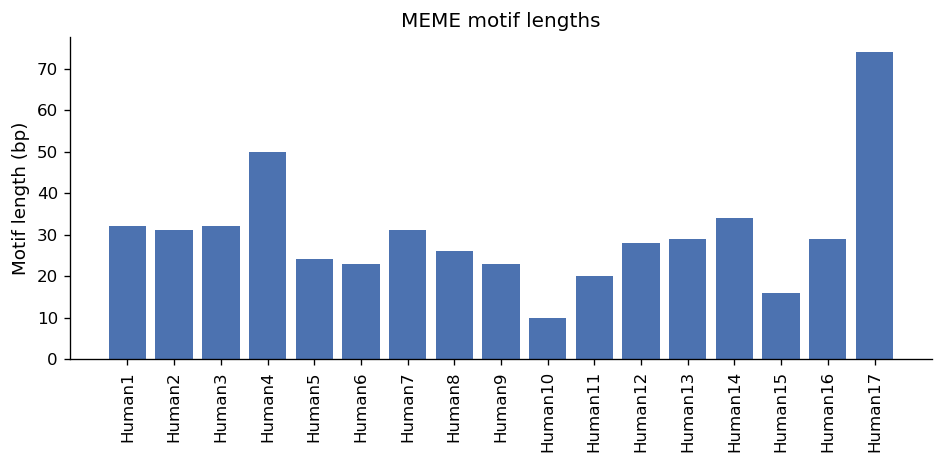

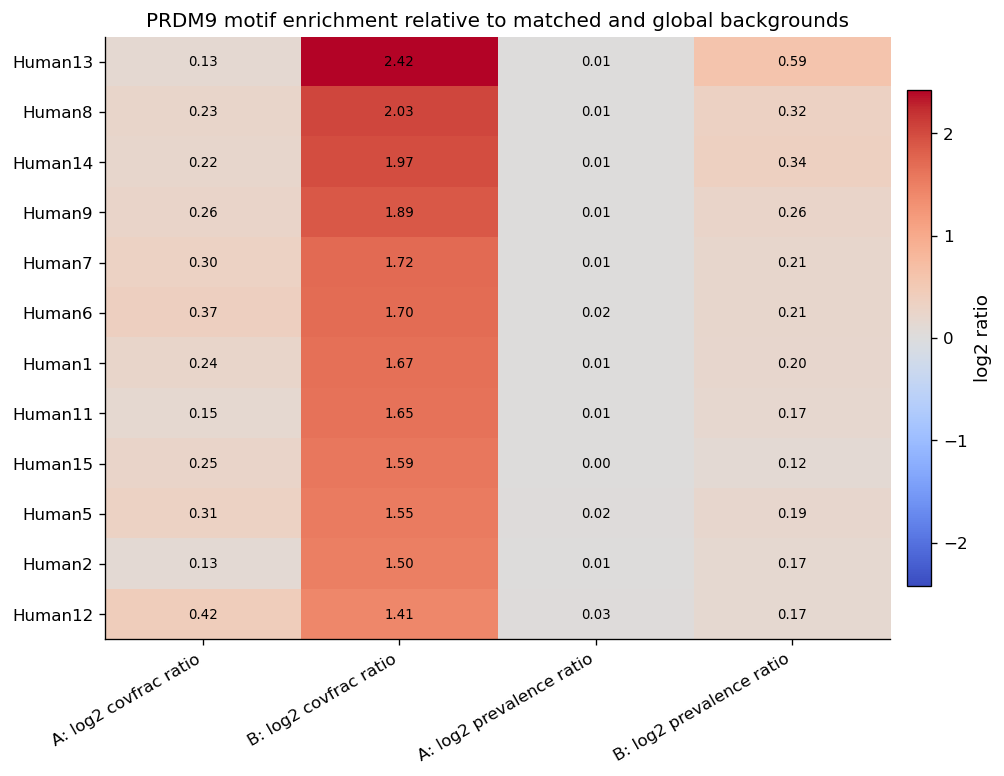

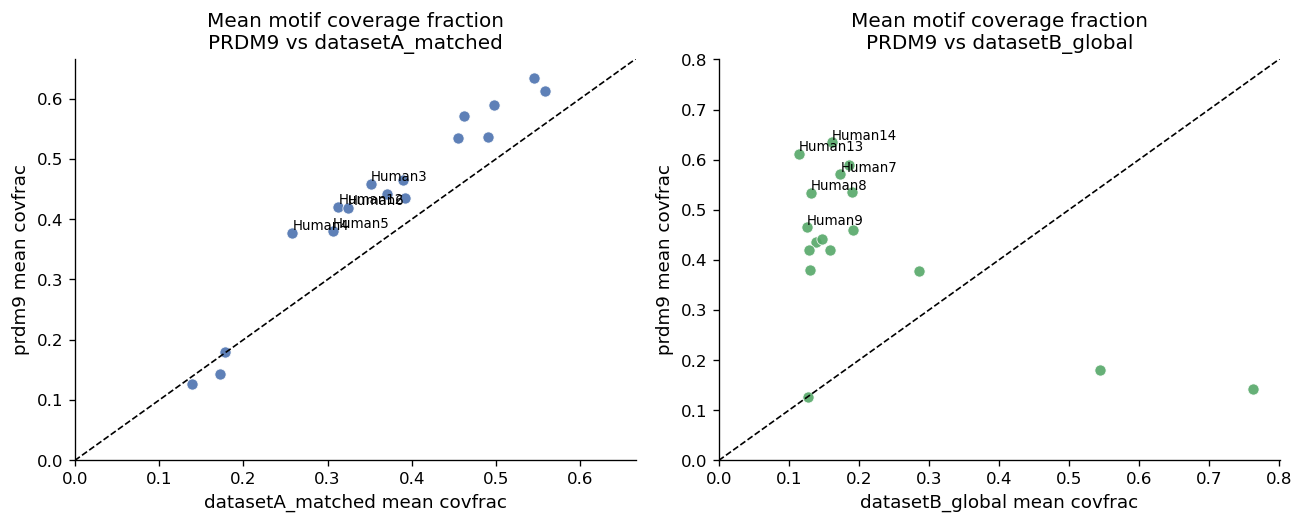

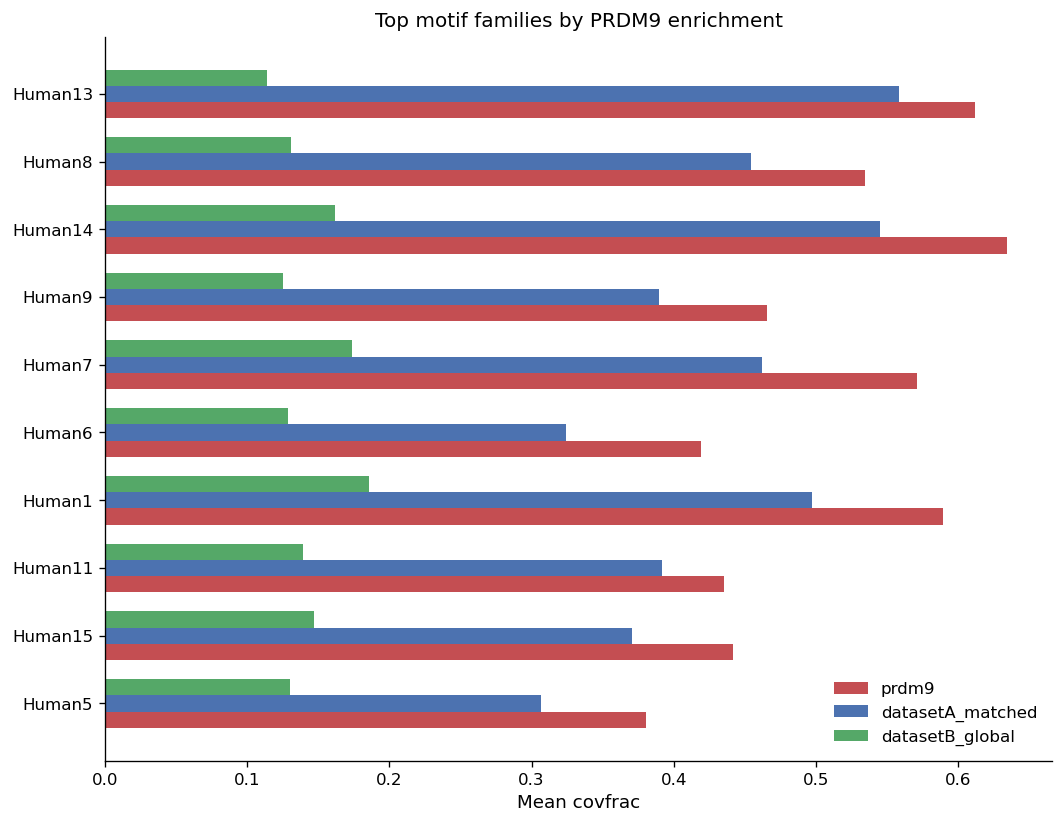

[04/16/26 18:12:15] INFO     Saved figures to data_prdm9_motifs_production/figures

In [8]:

# ------------------------------------------------------------------
# Validation figures
# ------------------------------------------------------------------
logger.info("[6/8] Building validation figures")

# 1) Motif length panel
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(motif_df))
ax.bar(x, motif_df["motif_length"].to_numpy(), color="#4C72B0", edgecolor="none")
ax.set_xticks(x)
ax.set_xticklabels(motif_df["motif_name"].tolist(), rotation=90)
ax.set_ylabel("Motif length (bp)")
ax.set_title("MEME motif lengths")
fig.tight_layout()
fig.savefig(FIGDIR / "motif_lengths.png", bbox_inches="tight")
plt.show()

# helper for selecting top motifs
top_order = (
    ratio_df.groupby("motif_name", as_index=False)["log2_mean_covfrac_ratio"]
    .max()
    .sort_values("log2_mean_covfrac_ratio", ascending=False)
)
top_motifs = top_order["motif_name"].head(min(12, len(top_order))).tolist()

# 2) Heatmap of PRDM9 enrichment over backgrounds
heat_rows = []
for motif in top_motifs:
    sub = ratio_df.loc[ratio_df["motif_name"] == motif].set_index("background")
    heat_rows.append({
        "motif_name": motif,
        "A: log2 covfrac ratio": sub.loc["datasetA_matched", "log2_mean_covfrac_ratio"],
        "B: log2 covfrac ratio": sub.loc["datasetB_global", "log2_mean_covfrac_ratio"],
        "A: log2 prevalence ratio": sub.loc["datasetA_matched", "log2_prevalence_ratio"],
        "B: log2 prevalence ratio": sub.loc["datasetB_global", "log2_prevalence_ratio"],
    })
heat_df = pd.DataFrame(heat_rows).set_index("motif_name")

fig, ax = plt.subplots(figsize=(8.5, max(4, 0.45 * len(heat_df) + 1.2)))
mat = heat_df.to_numpy(dtype=float)
vmax = max(1.0, float(np.nanmax(np.abs(mat))))
im = ax.imshow(mat, aspect="auto", cmap="coolwarm", vmin=-vmax, vmax=vmax)
ax.set_xticks(np.arange(heat_df.shape[1]))
ax.set_xticklabels(heat_df.columns.tolist(), rotation=30, ha="right")
ax.set_yticks(np.arange(heat_df.shape[0]))
ax.set_yticklabels(heat_df.index.tolist())
ax.set_title("PRDM9 motif enrichment relative to matched and global backgrounds")
for i in range(heat_df.shape[0]):
    for j in range(heat_df.shape[1]):
        ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=8)
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label("log2 ratio")
fig.tight_layout()
fig.savefig(FIGDIR / "motif_enrichment_heatmap.png", bbox_inches="tight")
plt.show()

# 3) Scatter: mean covfrac in PRDM9 vs backgrounds
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=False, sharey=False)
for ax, bg in zip(axes, ["datasetA_matched", "datasetB_global"]):
    merged = (
        windowset_summary.loc[windowset_summary["windowset"].isin(["prdm9", bg]), ["motif_name", "windowset", "mean_covfrac"]]
        .pivot(index="motif_name", columns="windowset", values="mean_covfrac")
        .reset_index()
    )
    x = merged[bg].to_numpy()
    y = merged["prdm9"].to_numpy()

    ax.scatter(x, y, s=45, alpha=0.9, color=PALETTE_WINDOWSET[bg], edgecolor="white", linewidth=0.5)
    lim = max(float(np.max(x)) if len(x) else 0, float(np.max(y)) if len(y) else 0) * 1.05
    lim = max(lim, 1e-4)
    ax.plot([0, lim], [0, lim], linestyle="--", linewidth=1, color="black")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel(f"{bg} mean covfrac")
    ax.set_ylabel("prdm9 mean covfrac")
    ax.set_title(f"Mean motif coverage fraction\nPRDM9 vs {bg}")

    # annotate top enriched motifs
    annot = ratio_df.loc[ratio_df["background"] == bg].sort_values("log2_mean_covfrac_ratio", ascending=False).head(min(5, len(ratio_df)))
    annot_names = annot["motif_name"].tolist()
    annot_sub = merged.loc[merged["motif_name"].isin(annot_names)]
    for row in annot_sub.itertuples(index=False):
        ax.text(getattr(row, bg), row.prdm9, row.motif_name, fontsize=8, ha="left", va="bottom")

fig.tight_layout()
fig.savefig(FIGDIR / "motif_covfrac_scatter.png", bbox_inches="tight")
plt.show()

# 4) Top motifs bar summary
top_for_bar = top_order["motif_name"].head(min(10, len(top_order))).tolist()
bar_df = (
    windowset_summary.loc[windowset_summary["motif_name"].isin(top_for_bar), ["motif_name", "windowset", "mean_covfrac"]]
    .copy()
)
bar_df["motif_name"] = pd.Categorical(bar_df["motif_name"], categories=top_for_bar[::-1], ordered=True)
bar_df = bar_df.sort_values("motif_name")

fig, ax = plt.subplots(figsize=(9, max(4, 0.55 * len(top_for_bar) + 1.5)))
width = 0.24
ypos = np.arange(len(top_for_bar))
for idx, ws in enumerate(["prdm9", "datasetA_matched", "datasetB_global"]):
    sub = bar_df.loc[bar_df["windowset"] == ws].set_index("motif_name").reindex(top_for_bar[::-1])
    ax.barh(
        ypos + (idx - 1) * width,
        sub["mean_covfrac"].to_numpy(),
        height=width,
        label=ws,
        color=PALETTE_WINDOWSET[ws],
    )
ax.set_yticks(ypos)
ax.set_yticklabels(top_for_bar[::-1])
ax.set_xlabel("Mean covfrac")
ax.set_title("Top motif families by PRDM9 enrichment")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGDIR / "motif_top_bar_summary.png", bbox_inches="tight")
plt.show()

logger.info(f"Saved figures to {FIGDIR}")


In [9]:

# ------------------------------------------------------------------
# Run metadata and final report
# ------------------------------------------------------------------
logger.info("[7/8] Writing metadata")

metadata = {
    "n_cpus": int(N_CPUS),
    "chunk_size": int(CHUNK_SIZE),
    "hit_threshold": float(HIT_THRESHOLD),
    "n_windows_total": int(len(windows)),
    "windowset_sizes": windows["WindowSet"].value_counts().sort_index().to_dict(),
    "n_motifs": int(len(motif_df)),
    "motif_lengths": {
        row.motif_name: int(row.motif_length)
        for row in motif_df.itertuples(index=False)
    },
    "mean_valid_base_frac_by_windowset": (
        feat_debug.groupby("WindowSet")["sequence__valid_base_frac"].mean().round(8).to_dict()
    ),
    "outputs": {
        "all_parquet": str(ALL_PARQUET),
        "debug_parquet": str(DEBUG_PARQUET),
        "motif_metadata_table": str(MOTIF_META_TABLE),
        "windowset_summary_table": str(WINDOWSET_SUMMARY_TABLE),
        "ratio_table": str(RATIO_TABLE),
        "figures_dir": str(FIGDIR),
        "log_file": str(LOG_FILE),
    },
    "method_notes": {
        "strand_rule": "Each genomic start is counted once if score > threshold on either strand.",
        "covfrac_rule": "Coverage is union coverage of hit intervals for each motif.",
        "background_model": "Uniform base background (0.25 each for A/C/G/T).",
        "ambiguous_bases": "Starts overlapping non-ACGT characters are excluded from hit calling.",
        "exported_features": ["hits", "covfrac"],
    },
}

with open(METADATA_JSON, "w") as f:
    json.dump(metadata, f, indent=2)

summary_table = Table(title="Run outputs", show_lines=False)
summary_table.add_column("Item")
summary_table.add_column("Value")

summary_table.add_row("All-window parquet", str(ALL_PARQUET))
summary_table.add_row("Debug parquet", str(DEBUG_PARQUET))
summary_table.add_row("Motif metadata", str(MOTIF_META_TABLE))
summary_table.add_row("Window-set summary", str(WINDOWSET_SUMMARY_TABLE))
summary_table.add_row("Ratio table", str(RATIO_TABLE))
summary_table.add_row("Figures", str(FIGDIR))
summary_table.add_row("Metadata JSON", str(METADATA_JSON))
summary_table.add_row("Log file", str(LOG_FILE))

console.print(summary_table)

display(pd.DataFrame([{
    "n_windows_total": metadata["n_windows_total"],
    "n_motifs": metadata["n_motifs"],
    "prdm9_windows": metadata["windowset_sizes"].get("prdm9", 0),
    "datasetA_windows": metadata["windowset_sizes"].get("datasetA_matched", 0),
    "datasetB_windows": metadata["windowset_sizes"].get("datasetB_global", 0),
}]))
logger.info("[8/8] Done")


                    INFO     [7/8] Writing metadata

                                             Run outputs                                             
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Item               ┃ Value                                                                        ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ All-window parquet │ data_prdm9_motifs_production/features/motif_features.parquet                 │
│ Debug parquet      │ data_prdm9_motifs_production/features/motif_features_with_qc.parquet         │
│ Motif metadata     │ data_prdm9_motifs_production/tables/motif_metadata.tsv                       │
│ Window-set summary │ data_prdm9_motifs_production/tables/motif_windowset_summary.tsv              │
│ Ratio table        │ data_prdm9_motifs_production/tables/motif_ratio_summary.tsv                  │
│ Figures            │ data_prdm9_motifs_production/figures                                         │
│ Metadata JSON      │ data_prdm9_motifs_production/metadata/motif_feature_generation_metadata.json │
│ Log file           │ data_prdm9_motifs_production/logs/prdm9_motif_feature_generation.log         │
└────────────────────┴──────────────────────────────────────────────────────────────────────────────┘

,n_windows_total,n_motifs,prdm9_windows,datasetA_windows,datasetB_windows
0,424060,17,60580,181740,181740


                    INFO     [8/8] Done